In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Rows and columns:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Rows and columns: (541909, 8)

Column types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

print("Negative or zero quantities:", (df["Quantity"] <= 0).sum())

print("Negative or zero prices:", (df["UnitPrice"] <= 0).sum())

print("Cancelled invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Duplicate rows: 5268
Negative or zero quantities: 10624
Negative or zero prices: 2517
Cancelled invoices: 9288
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [5]:
clean_df = df.copy()

# Remove rows without a customer ID
clean_df = clean_df.dropna(subset=["CustomerID"])

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Keep completed purchases only
clean_df = clean_df[clean_df["Quantity"] > 0]
clean_df = clean_df[clean_df["UnitPrice"] > 0]

# Remove cancelled invoices
clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Convert CustomerID from decimal to whole number
clean_df["CustomerID"] = clean_df["CustomerID"].astype(int)

print("Original rows:", len(df))
print("Clean rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

clean_df.head()

Original rows: 541909
Clean rows: 392692
Rows removed: 149217


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [6]:
clean_df["TotalSales"] = clean_df["Quantity"] * clean_df["UnitPrice"]

clean_df[["Quantity", "UnitPrice", "TotalSales"]].head()

,Quantity,UnitPrice,TotalSales
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [7]:
print("Unique customers:", clean_df["CustomerID"].nunique())

print("Total orders:", clean_df["InvoiceNo"].nunique())

print("Total sales: $", round(clean_df["TotalSales"].sum(), 2))

print("Average order value: $", round(
    clean_df.groupby("InvoiceNo")["TotalSales"].sum().mean(), 2
))

Unique customers: 4338
Total orders: 18532
Total sales: $ 8887208.89
Average order value: $ 479.56


In [8]:
# Set analysis date to one day after the last transaction
analysis_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = clean_df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (analysis_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalSales": "sum"
}).reset_index()

rfm.columns = ["CustomerID", "Recency", "Frequency", "Monetary"]

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [9]:
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [10]:
# Score each customer from 1 to 4 based on quartiles

rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    4,
    labels=[4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    4,
    labels=[1, 2, 3, 4]
)

# Convert scores to numbers
rfm[["R_Score", "F_Score", "M_Score"]] = (
    rfm[["R_Score", "F_Score", "M_Score"]].astype(int)
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,1,77183.60,1,1,4
1,12347,2,7,4310.00,4,4,4
2,12348,75,4,1797.24,2,3,4
3,12349,19,1,1757.55,3,1,4
4,12350,310,1,334.40,1,1,2


In [11]:
def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 3 and f >= 3 and m >= 3:
        return "High-Value Loyalists"
    elif r >= 3 and f <= 2:
        return "New & Promising"
    elif r <= 2 and f >= 3 and m >= 3:
        return "At-Risk High Value"
    elif r == 1 and f <= 2:
        return "Lapsed"
    else:
        return "Regular Customers"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

rfm[["CustomerID", "Recency", "Frequency", "Monetary", "Segment"]].head(10)

,CustomerID,Recency,Frequency,Monetary,Segment
0,12346,326,1,77183.60,Lapsed
1,12347,2,7,4310.00,High-Value Loyalists
2,12348,75,4,1797.24,At-Risk High Value
3,12349,19,1,1757.55,New & Promising
4,12350,310,1,334.40,Lapsed
5,12352,36,8,2506.04,High-Value Loyalists
6,12353,204,1,89.00,Lapsed
7,12354,232,1,1079.40,Lapsed
8,12355,214,1,459.40,Lapsed
9,12356,23,3,2811.43,High-Value Loyalists


In [12]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Spend=("Monetary", "mean"),
    Total_Sales=("Monetary", "sum")
).round(2)

segment_summary["Customer_Percent"] = (
    segment_summary["Customers"] / len(rfm) * 100
).round(1)

segment_summary.sort_values("Customers", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Spend,Total_Sales,Customer_Percent
Segment,,,,,,
High-Value Loyalists,1317,17.11,9.39,4926.88,6488695.17,30.4
Regular Customers,1004,83.91,2.00,506.26,508281.50,23.1
Lapsed,903,254.87,1.21,481.56,434847.13,20.8
New & Promising,665,25.25,1.45,751.28,499604.37,15.3
At-Risk High Value,449,106.22,4.68,2128.69,955780.72,10.4


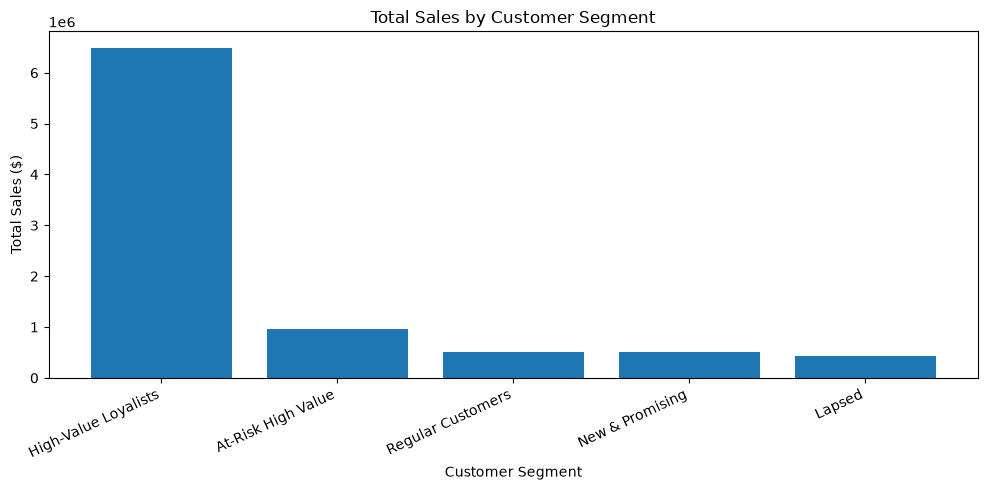

In [13]:
segment_chart = segment_summary.sort_values("Total_Sales", ascending=False)

plt.figure(figsize=(10, 5))

plt.bar(
    segment_chart.index,
    segment_chart["Total_Sales"]
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [14]:
segment_summary["Sales_Percent"] = (
    segment_summary["Total_Sales"] / segment_summary["Total_Sales"].sum() * 100
).round(1)

segment_summary[
    ["Customers", "Customer_Percent", "Total_Sales", "Sales_Percent"]
].sort_values("Sales_Percent", ascending=False)

,Customers,Customer_Percent,Total_Sales,Sales_Percent
Segment,,,,
High-Value Loyalists,1317,30.4,6488695.17,73.0
At-Risk High Value,449,10.4,955780.72,10.8
Regular Customers,1004,23.1,508281.50,5.7
New & Promising,665,15.3,499604.37,5.6
Lapsed,903,20.8,434847.13,4.9


In [15]:
rfm["Customer_Type"] = np.where(
    rfm["Frequency"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_type_summary = rfm["Customer_Type"].value_counts().to_frame("Customers")

customer_type_summary["Percent"] = (
    customer_type_summary["Customers"] / len(rfm) * 100
).round(1)

customer_type_summary

,Customers,Percent
Customer_Type,,
Repeat Customer,2845,65.6
One-Time Customer,1493,34.4


In [16]:
repeat_ids = rfm.loc[
    rfm["Customer_Type"] == "Repeat Customer",
    "CustomerID"
]

repeat_purchases = clean_df[
    clean_df["CustomerID"].isin(repeat_ids)
]

top_repeat_products = (
    repeat_purchases.groupby("Description")
    .agg(
        Repeat_Customers=("CustomerID", "nunique"),
        Quantity_Sold=("Quantity", "sum"),
        Sales=("TotalSales", "sum")
    )
    .sort_values("Repeat_Customers", ascending=False)
    .head(10)
)

top_repeat_products.round(2)

,Repeat_Customers,Quantity_Sold,Sales
Description,,,
REGENCY CAKESTAND 3 TIER,741,11766,135081.55
WHITE HANGING HEART T-LIGHT HOLDER,698,35172,96086.00
PARTY BUNTING,605,14547,65375.93
ASSORTED COLOUR BIRD ORNAMENT,565,33724,53850.52
JUMBO BAG RED RETROSPOT,557,44428,81936.20
PACK OF 72 RETROSPOT CAKE CASES,554,31351,15246.83
SET OF 3 CAKE TINS PANTRY DESIGN,537,6523,31005.25
PAPER CHAIN KIT 50'S CHRISTMAS,528,14690,40070.18
SPOTTY BUNTING,515,7430,34504.70


In [17]:
product_customer_type = (
    clean_df.merge(
        rfm[["CustomerID", "Customer_Type"]],
        on="CustomerID",
        how="left"
    )
    .groupby(["Description", "Customer_Type"])["CustomerID"]
    .nunique()
    .unstack(fill_value=0)
)

product_customer_type["Total_Customers"] = (
    product_customer_type["Repeat Customer"] +
    product_customer_type["One-Time Customer"]
)

product_customer_type["Repeat_Rate"] = (
    product_customer_type["Repeat Customer"] /
    product_customer_type["Total_Customers"] * 100
)

# Only keep products purchased by at least 100 unique customers
loyalty_products = (
    product_customer_type[
        product_customer_type["Total_Customers"] >= 100
    ]
    .sort_values("Repeat_Rate", ascending=False)
    .head(10)
)

loyalty_products.round(1)

Customer_Type,One-Time Customer,Repeat Customer,Total_Customers,Repeat_Rate
Description,,,,
LUNCH BAG RED VINTAGE DOILY,1,104,105,99.0
VINTAGE DOILY JUMBO BAG RED,5,181,186,97.3
JUMBO BAG PAISLEY PARK,7,223,230,97.0
GIN AND TONIC MUG,4,106,110,96.4
STRAWBERRY PICNIC BAG,6,140,146,95.9
LUNCH BAG PAISLEY PARK,10,223,233,95.7
PEG BAG APPLES DESIGN,7,137,144,95.1
SET 3 SONG BIRD PAPER EGGS ASSORTED,6,116,122,95.1
VINTAGE BELLS GARLAND,6,110,116,94.8


In [18]:
# Calculate total value of each order
orders = (
    clean_df.groupby(["CustomerID", "InvoiceNo"])["TotalSales"]
    .sum()
    .reset_index()
)

# Average order value for each customer
customer_aov = (
    orders.groupby("CustomerID")["TotalSales"]
    .mean()
    .reset_index(name="Avg_Order_Value")
)

# Add AOV to our customer segmentation table
segment_behavior = rfm.merge(
    customer_aov,
    on="CustomerID",
    how="left"
)

segment_behavior_summary = (
    segment_behavior.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Orders=("Frequency", "mean"),
        Avg_Order_Value=("Avg_Order_Value", "mean"),
        Avg_Customer_Spend=("Monetary", "mean")
    )
    .round(2)
)

segment_behavior_summary.sort_values(
    "Avg_Customer_Spend",
    ascending=False
)

,Customers,Avg_Orders,Avg_Order_Value,Avg_Customer_Spend
Segment,,,,
High-Value Loyalists,1317,9.39,444.99,4926.88
At-Risk High Value,449,4.68,499.83,2128.69
New & Promising,665,1.45,471.37,751.28
Regular Customers,1004,2.00,318.40,506.26
Lapsed,903,1.21,407.68,481.56


In [19]:
at_risk = segment_summary.loc["At-Risk High Value"]

print("At-Risk High Value customers:", int(at_risk["Customers"]))
print("Share of customers:", at_risk["Customer_Percent"], "%")
print("Sales represented: $", round(at_risk["Total_Sales"], 2))
print("Share of sales:", at_risk["Sales_Percent"], "%")

print("\nAverage behavior:")
print("Average orders:", segment_behavior_summary.loc["At-Risk High Value", "Avg_Orders"])
print("Average order value: $", segment_behavior_summary.loc["At-Risk High Value", "Avg_Order_Value"])
print("Average customer spend: $", segment_behavior_summary.loc["At-Risk High Value", "Avg_Customer_Spend"])

At-Risk High Value customers: 449
Share of customers: 10.4 %
Sales represented: $ 955780.72
Share of sales: 10.8 %

Average behavior:
Average orders: 4.68
Average order value: $ 499.83
Average customer spend: $ 2128.69


In [20]:
# Add customer segments to the transaction-level data
tableau_data = clean_df.merge(
    rfm[["CustomerID", "Segment", "Customer_Type"]],
    on="CustomerID",
    how="left"
)

# Export transaction-level dataset for Tableau
tableau_data.to_csv(
    "customer_loyalty_tableau.csv",
    index=False
)

# Export customer-level RFM dataset
rfm.to_csv(
    "customer_segments.csv",
    index=False
)

print("Files exported successfully!")
print("Tableau rows:", len(tableau_data))
print("Customer rows:", len(rfm))

Files exported successfully!
Tableau rows: 392692
Customer rows: 4338
